In [19]:
import pandas as pd
df = pd.read_csv("../data/framingham.csv")
df.shape

(4238, 16)

In [20]:
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [21]:
df.isna().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [22]:
df["TenYearCHD"].value_counts(normalize=True)

TenYearCHD
0    0.848042
1    0.151958
Name: proportion, dtype: float64

In [23]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
male,4238.0,0.429212,0.495022,0.00,0.00,0.0,1.000,1.0
age,4238.0,49.584946,8.572160,32.00,42.00,49.0,56.000,70.0
education,4133.0,1.978950,1.019791,1.00,1.00,2.0,3.000,4.0
currentSmoker,4238.0,0.494101,0.500024,0.00,0.00,0.0,1.000,1.0
cigsPerDay,4209.0,9.003089,11.920094,0.00,0.00,0.0,20.000,70.0
BPMeds,4185.0,0.029630,0.169584,0.00,0.00,0.0,0.000,1.0
prevalentStroke,4238.0,0.005899,0.076587,0.00,0.00,0.0,0.000,1.0
prevalentHyp,4238.0,0.310524,0.462763,0.00,0.00,0.0,1.000,1.0
diabetes,4238.0,0.025720,0.158316,0.00,0.00,0.0,0.000,1.0
totChol,4188.0,236.721585,44.590334,107.00,206.00,234.0,263.000,696.0


## Step 2 – Clean

In [24]:
# Non-smokers with missing cigarette count -> 0
df.loc[(df["currentSmoker"] == 0) & (df["cigsPerDay"].isna()), "cigsPerDay"] = 0

# Education is not a clinical risk factor
df = df.drop(columns=["education"])

df.isna().sum()

male                 0
age                  0
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

## Step 3 – Split

In [25]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["TenYearCHD"])
y = df["TenYearCHD"]

X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42)
X_cal, X_test, y_cal, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)

print("Train:", X_train.shape, " Cal:", X_cal.shape, " Test:", X_test.shape)
print("Positive rate:", round(y_train.mean(), 3), round(y_cal.mean(), 3), round(y_test.mean(), 3))

Train: (2542, 14)  Cal: (848, 14)  Test: (848, 14)
Positive rate: 0.152 0.152 0.152


## Step 4 – Logistic Regression (baseline)

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

lr = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # fill missing values
    ("scale", StandardScaler()),                    # put all features on same scale
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced")),
])

lr.fit(X_train, y_train)

p_lr_test = lr.predict_proba(X_test)[:, 1]
print("Logistic Regression AUC:", round(roc_auc_score(y_test, p_lr_test), 3))

Logistic Regression AUC: 0.696


## Step 5 – XGBoost

In [27]:
from xgboost import XGBClassifier

# Weight for the minority class (about 5.6 healthy patients per sick patient)
w = (y_train == 0).sum() / (y_train == 1).sum()
print("Class weight:", round(w, 2))

xgb = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        n_estimators=300,      # number of trees
        max_depth=3,           # how deep each tree can go
        learning_rate=0.03,    # how fast it learns
        subsample=0.8,         # use 80% of rows per tree (reduces overfitting)
        colsample_bytree=0.8,  # use 80% of features per tree
        scale_pos_weight=w,    # handle the 15% imbalance
        random_state=42,
    )),
])

xgb.fit(X_train, y_train)

p_xgb_test = xgb.predict_proba(X_test)[:, 1]
print("XGBoost AUC:", round(roc_auc_score(y_test, p_xgb_test), 3))

Class weight: 5.59
XGBoost AUC: 0.679


## Step 6 – Sensitivity & Specificity

In [28]:
from sklearn.metrics import confusion_matrix

def sens_spec(y_true, probs, threshold=0.5):
    pred = (probs >= threshold).astype(int)          # risk above threshold = "high risk"
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    sens = tp / (tp + fn)                            # sick patients caught
    spec = tn / (tn + fp)                            # healthy patients cleared
    return round(sens, 3), round(spec, 3), tp, fn, tn, fp

for name, p in [("Logistic Regression", p_lr_test), ("XGBoost", p_xgb_test)]:
    sens, spec, tp, fn, tn, fp = sens_spec(y_test, p)
    print(f"{name:20s} Sensitivity={sens}  Specificity={spec}  "
          f"(caught {tp} of {tp+fn} sick, cleared {tn} of {tn+fp} healthy)")

Logistic Regression  Sensitivity=0.581  Specificity=0.698  (caught 75 of 129 sick, cleared 502 of 719 healthy)
XGBoost              Sensitivity=0.55  Specificity=0.726  (caught 71 of 129 sick, cleared 522 of 719 healthy)


## Step 6b – Choose threshold

In [29]:
from sklearn.metrics import roc_curve

def best_threshold(y_true, probs):
    # Youden's J: the cut-off that best balances sensitivity and specificity
    fpr, tpr, thr = roc_curve(y_true, probs)
    return thr[(tpr - fpr).argmax()]

# Choose the threshold on the CALIBRATION set
t_lr  = best_threshold(y_cal, lr.predict_proba(X_cal)[:, 1])
t_xgb = best_threshold(y_cal, xgb.predict_proba(X_cal)[:, 1])
print("Chosen thresholds -> LR:", round(t_lr, 3), " XGB:", round(t_xgb, 3))

# Then report on the TEST set
for name, p, t in [("Logistic Regression", p_lr_test, t_lr), ("XGBoost", p_xgb_test, t_xgb)]:
    sens, spec, tp, fn, tn, fp = sens_spec(y_test, p, threshold=t)
    print(f"{name:20s} Sensitivity={sens}  Specificity={spec}  (caught {tp} of {tp+fn} sick)")

Chosen thresholds -> LR: 0.397  XGB: 0.308
Logistic Regression  Sensitivity=0.721  Specificity=0.541  (caught 93 of 129 sick)
XGBoost              Sensitivity=0.791  Specificity=0.416  (caught 102 of 129 sick)


## Step 7 – Calibration

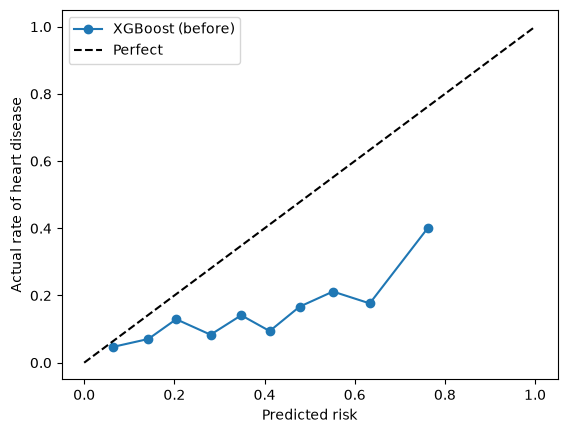

Brier score before: 0.194


In [30]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

frac, mean = calibration_curve(y_test, p_xgb_test, n_bins=10, strategy="quantile")
plt.plot(mean, frac, "o-", label="XGBoost (before)")
plt.plot([0, 1], [0, 1], "k--", label="Perfect")
plt.xlabel("Predicted risk"); plt.ylabel("Actual rate of heart disease")
plt.legend(); plt.show()

print("Brier score before:", round(brier_score_loss(y_test, p_xgb_test), 3))

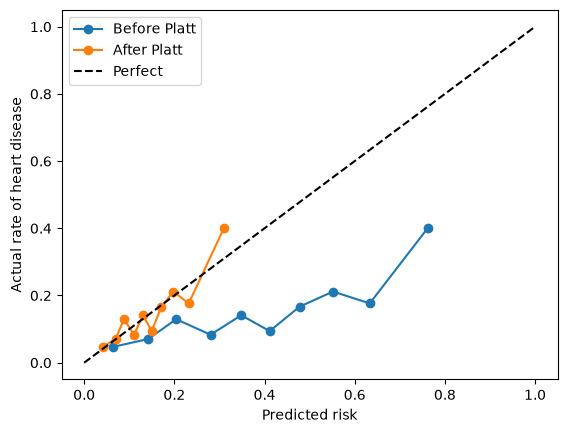

Brier score before: 0.194
Brier score after: 0.121
AUC after (should be unchanged): 0.679


In [31]:
import numpy as np

def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

# Learn the correction on the CALIBRATION set
p_xgb_cal = xgb.predict_proba(X_cal)[:, 1]
platt = LogisticRegression().fit(to_logit(p_xgb_cal), y_cal)

# Apply it to the TEST set
p_xgb_test_cal = platt.predict_proba(to_logit(p_xgb_test))[:, 1]

# Plot before vs after
frac2, mean2 = calibration_curve(y_test, p_xgb_test_cal, n_bins=10, strategy="quantile")
plt.plot(mean, frac, "o-", label="Before Platt")
plt.plot(mean2, frac2, "o-", label="After Platt")
plt.plot([0, 1], [0, 1], "k--", label="Perfect")
plt.xlabel("Predicted risk"); plt.ylabel("Actual rate of heart disease")
plt.legend()
plt.savefig("../outputs/calibration_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

print("Brier score before:", round(brier_score_loss(y_test, p_xgb_test), 3))
print("Brier score after:", round(brier_score_loss(y_test, p_xgb_test_cal), 3))
print("AUC after (should be unchanged):", round(roc_auc_score(y_test, p_xgb_test_cal), 3))

## Step 8 – Explainability (SHAP)

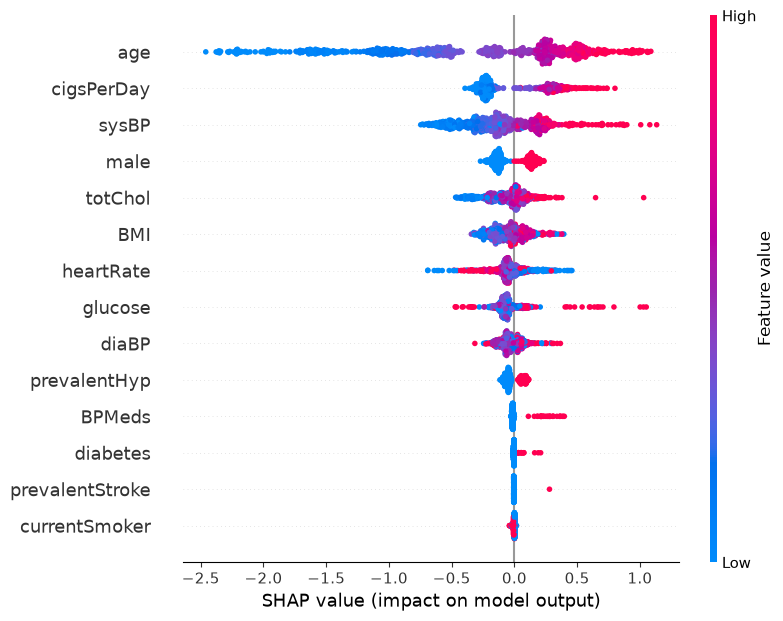

In [32]:
import shap

# SHAP needs the same filled-in data the model saw
X_test_filled = pd.DataFrame(xgb.named_steps["impute"].transform(X_test),
                             columns=X_test.columns, index=X_test.index)

explainer = shap.TreeExplainer(xgb.named_steps["model"])
sv = explainer(X_test_filled)

shap.plots.beeswarm(sv, max_display=14, show=False)
plt.savefig("../outputs/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

Predicted 10-year risk: 49%
Actually got heart disease: Yes
male                 0.00
age                 67.00
currentSmoker        0.00
cigsPerDay           0.00
BPMeds               1.00
prevalentStroke      0.00
prevalentHyp         1.00
diabetes             1.00
totChol            303.00
sysBP              204.00
diaBP               96.00
BMI                 27.86
heartRate           75.00
glucose            394.00
Name: 2909, dtype: float64


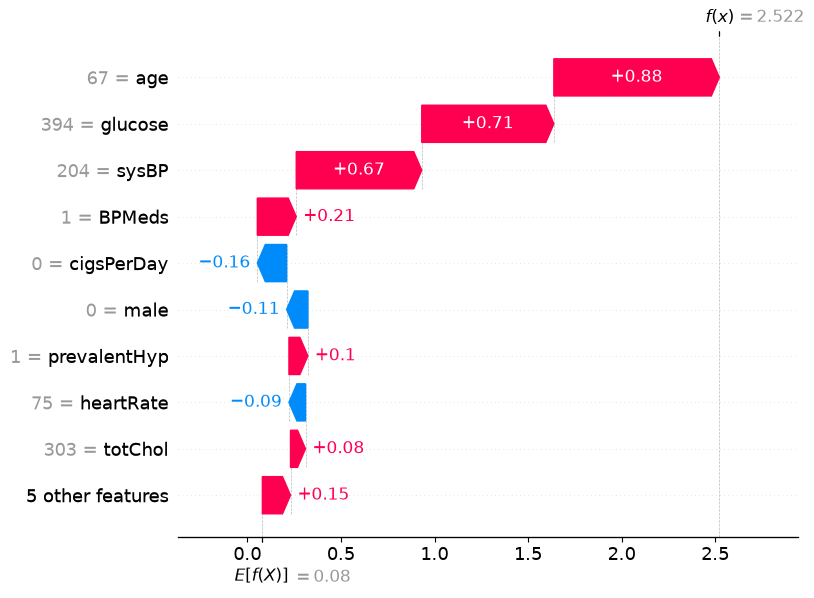

In [33]:
i = int(np.argmax(p_xgb_test_cal))          # the highest-risk patient in the test set
print(f"Predicted 10-year risk: {p_xgb_test_cal[i]*100:.0f}%")
print("Actually got heart disease:", "Yes" if y_test.iloc[i] == 1 else "No")
print(X_test_filled.iloc[i])

shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.savefig("../outputs/shap_patient_example.png", dpi=150, bbox_inches="tight")
plt.show()